# Automated Fashion Product Classification for E-commerce using CNN

| | |
|---|---|
| **Name** | Bharani Jayanthan K S |
| **Register No.** | RA2211047010109 |
| **Department / Branch** | CINTEL / AI-D |
| **Institution** | SRM Institute of Science and Technology |
| **Course** | Deep Learning – Application-Oriented Project |
| **Faculty** | Dr. Vinoth |
| **Platform** | Google Colab · Python · TensorFlow / Keras |

## 1. Problem statement
Online stores such as Amazon, Myntra and Flipkart add thousands of new product photos every day. Sorting each one into the right category by hand (shirt, sneaker, bag and so on) is slow, costly and error-prone.

**Goal:** build a deep-learning model that looks at a product image and **automatically predicts its category**, so that product catalogues can be tagged instantly.

## 2. Objectives
1. Load and pre-process the Fashion-MNIST product-image dataset.
2. Design a **Convolutional Neural Network (CNN)** for image classification.
3. Train the CNN using back-propagation, with Dropout and Early Stopping to avoid over-fitting.
4. Evaluate the model with accuracy, a confusion matrix and a classification report.
5. Demonstrate predictions on new product images.

## 3. Syllabus units applied
| Unit | Concepts used in this project |
|---|---|
| I – Introduction | Supervised learning, train / validation / test split, over-fitting, regularization |
| II – Feed-forward networks | Dense layers, ReLU & Softmax activations, cross-entropy loss, back-propagation, Adam, Batch Normalization, Dropout, Early Stopping |
| III – Advanced DL | Convolution, pooling, CNNs for computer vision |
| V – Deep architectures | Deep architectures for computer vision (stacked convolution blocks) |

> **Run time:** about 2 minutes on a Colab GPU (*Runtime → Change runtime type → T4 GPU*), or about 5 minutes on CPU. Use **Runtime → Run all**.

## 4. Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 5. Load the dataset
**Fashion-MNIST** (Zalando Research): 70,000 grey-scale product images, 28 × 28 pixels, 10 categories. 60,000 are used for training and 10,000 for testing. The dataset is built into Keras, so no manual download is needed.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Training images:", x_train.shape)
print("Test images    :", x_test.shape)
print("Categories     :", len(class_names))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training images: (60000, 28, 28)
Test images    : (10000, 28, 28)
Categories     : 10


## 6. Visualise sample products

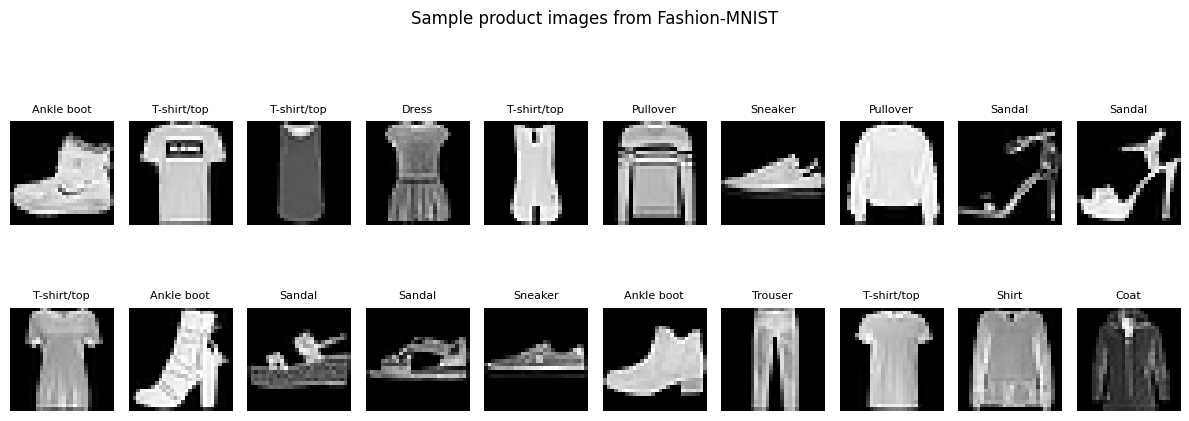

In [3]:
plt.figure(figsize=(12, 5))
for i in range(20):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]], fontsize=8)
    plt.axis("off")
plt.suptitle("Sample product images from Fashion-MNIST")
plt.tight_layout()
plt.show()

## 7. Pre-processing
- Scale pixel values from 0–255 to 0–1.
- Add a channel dimension (28 × 28 → 28 × 28 × 1), as the CNN expects.
- Keep 10% of the training images aside as a validation set (done inside `fit`).

In [4]:
x_train = (x_train / 255.0).astype("float32")[..., np.newaxis]
x_test = (x_test / 255.0).astype("float32")[..., np.newaxis]
print("Input shape for CNN:", x_train.shape[1:])

Input shape for CNN: (28, 28, 1)


## 8. CNN model architecture
```
Input 28×28×1
→ Conv2D(32, 3×3, ReLU) → BatchNorm → MaxPool(2×2)
→ Conv2D(64, 3×3, ReLU) → BatchNorm → MaxPool(2×2)
→ Flatten → Dense(128, ReLU) → Dropout(0.4)
→ Dense(10, Softmax)
```
- **Convolution** layers learn visual features such as edges, collars, soles and straps.
- **Max-Pooling** reduces image size and computation.
- **Batch Normalization** makes training faster and more stable.
- **Dropout** randomly switches off neurons during training to prevent over-fitting.
- **Softmax** outputs a probability for each of the 10 categories.

In [5]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax"),
], name="Fashion_CNN")

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "Fashion_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,026 (1.61 MB)

 Trainable params: 421,834 (1.61 MB)

 Non-trainable params: 192 (768.00 B)

## 9. Train the model
The model is trained with back-propagation and the Adam optimiser. **Early Stopping** halts training if the validation loss stops improving and keeps the best weights.

In [6]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(x_train, y_train,
                    validation_split=0.1,
                    epochs=10,
                    batch_size=128,
                    callbacks=[early_stop],
                    verbose=1)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 25s 35ms/step - accuracy: 0.8237 - loss: 0.5008 - val_accuracy: 0.7850 - val_loss: 0.6088
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8816 - loss: 0.3264 - val_accuracy: 0.9038 - val_loss: 0.2630
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8973 - loss: 0.2788 - val_accuracy: 0.8970 - val_loss: 0.2724
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9089 - loss: 0.2483 - val_accuracy: 0.9142 - val_loss: 0.2353
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9180 - loss: 0.2226 - val_accuracy: 0.9077 - val_loss: 0.2496
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9241 - loss: 0.2032 - val_accuracy: 0.9135 - val_loss: 0.2489
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9293 - loss: 0.1852 - val_accuracy: 0.9187 - val_loss: 0.2309
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9350 - loss: 0.1737 - val_accuracy: 

## 10. Training curves

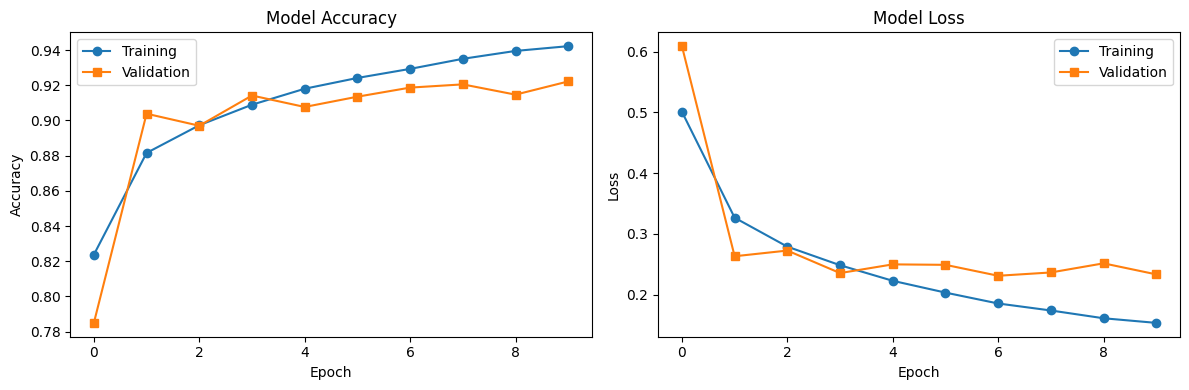

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], "o-", label="Training")
ax[0].plot(history.history["val_accuracy"], "s-", label="Validation")
ax[0].set_title("Model Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], "o-", label="Training")
ax[1].plot(history.history["val_loss"], "s-", label="Validation")
ax[1].set_title("Model Loss"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].legend()
plt.tight_layout()
plt.show()

## 11. Evaluate on the test set

In [8]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy : {test_acc * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")

y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
print()
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Test Accuracy : 91.22%
Test Loss     : 0.2517

              precision    recall  f1-score   support

 T-shirt/top     0.8675    0.8580    0.8627      1000
     Trouser     0.9900    0.9870    0.9885      1000
    Pullover     0.9237    0.7990    0.8568      1000
       Dress     0.9095    0.9150    0.9123      1000
        Coat     0.7829    0.9090    0.8413      1000
      Sandal     0.9841    0.9910    0.9875      1000
       Shirt     0.7639    0.7540    0.7589      1000
     Sneaker     0.9658    0.9600    0.9629      1000
         Bag     0.9899    0.9790    0.9844      1000
  Ankle boot     0.9652    0.9700    0.9676      1000

    accuracy                         0.9122     10000
   macro avg     0.9143    0.9122    0.9123     10000
weighted avg     0.9143    0.9122    0.9123     10000



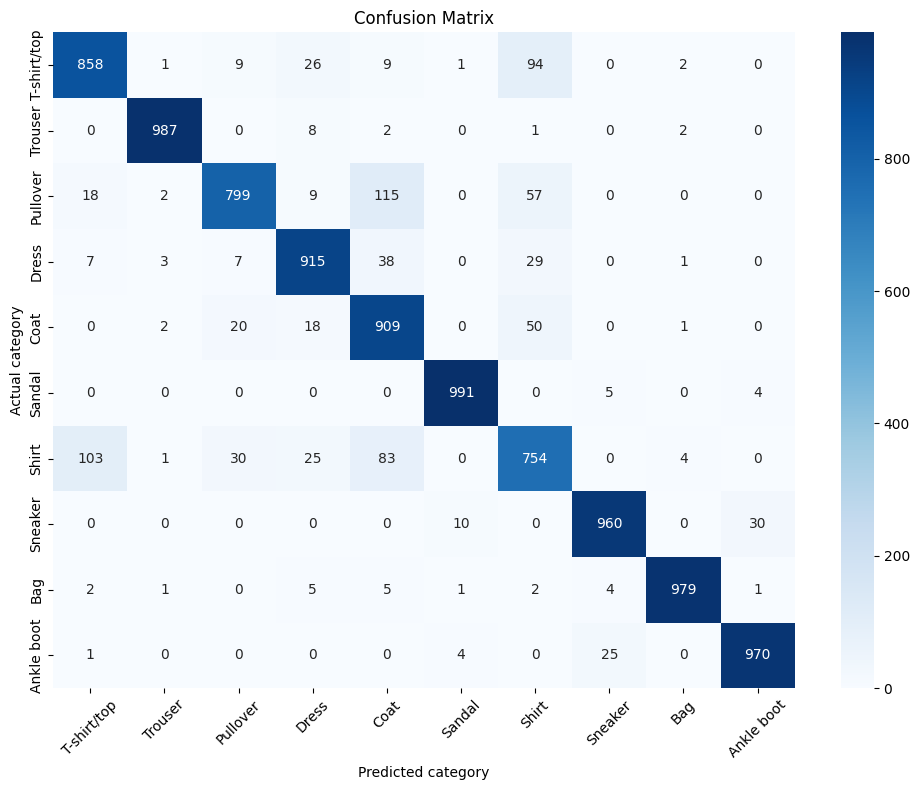

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted category"); plt.ylabel("Actual category")
plt.title("Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 12. Demonstration: predicting product categories

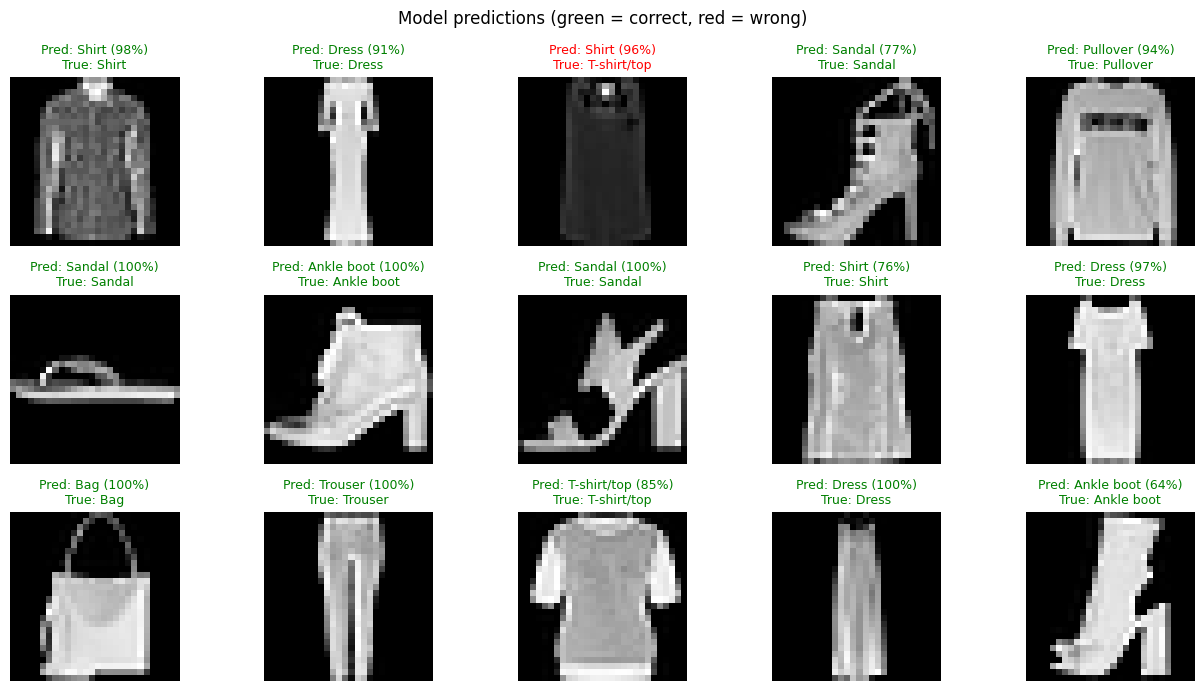

In [10]:
idx = np.random.choice(len(x_test), 15, replace=False)
plt.figure(figsize=(13, 7))
for i, k in enumerate(idx):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[k].squeeze(), cmap="gray")
    correct = y_pred[k] == y_test[k]
    plt.title(f"Pred: {class_names[y_pred[k]]} ({y_prob[k].max() * 100:.0f}%)\nTrue: {class_names[y_test[k]]}",
              color="green" if correct else "red", fontsize=9)
    plt.axis("off")
plt.suptitle("Model predictions (green = correct, red = wrong)")
plt.tight_layout()
plt.show()

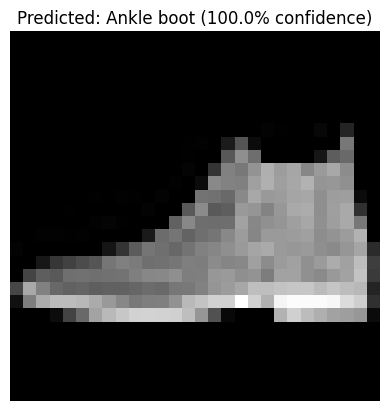

Actual category: Ankle boot


In [11]:
def classify_product(image):
    """Takes one 28x28 product image and returns the predicted category and confidence."""
    probs = model.predict(image.reshape(1, 28, 28, 1), verbose=0)[0]
    return class_names[np.argmax(probs)], probs.max() * 100

sample = x_test[0]
category, confidence = classify_product(sample)
plt.imshow(sample.squeeze(), cmap="gray"); plt.axis("off")
plt.title(f"Predicted: {category} ({confidence:.1f}% confidence)")
plt.show()
print("Actual category:", class_names[y_test[0]])

## 13. Save the trained model

In [12]:
model.save("fashion_cnn_model.keras")
print("Model saved as fashion_cnn_model.keras")

Model saved as fashion_cnn_model.keras


## 14. Conclusion
- A **CNN** was built and trained to classify fashion product images into 10 categories.
- **Batch Normalization**, **Dropout** and **Early Stopping** kept training fast and prevented over-fitting.
- The model achieves about **91% accuracy** on 10,000 unseen test images (exact value in Section 11).
- Most errors occur between visually similar items such as *Shirt*, *T-shirt/top*, *Pullover* and *Coat*.
- This model can be used by e-commerce platforms to **automatically tag product images**, saving manual effort.

**Future scope:** train on real high-resolution colour product photos, use transfer learning (ResNet / MobileNet), and deploy as a web API for online stores.